You’ve already learned and coded the multi-head attention mechanism, one of the
core components of LLMs. Now, we will code the other building blocks of an LLM
and assemble them into a GPT-like model that we will train in the next chapter to
generate human-like text

![image.png](attachment:0465896d-bf0d-4a56-9496-e08bba173fd3.png)

# Coding an LLM architecture
------------

LLMs, such as GPT (which stands for generative pretrained transformer), are large deep
neural network architectures designed to generate new text one word (or token) at a
time. However, despite their size, the model architecture is less complicated than you
might think, since many of its components are repeated.

We have already covered several aspects of the LLM architecture, such as input
tokenization and embedding and the masked multi-head attention module. Now, we
will implement the core structure of the GPT model, including its transformer blocks,
which we will later train to generate human-like text.

![image.png](attachment:92fe6090-d83d-404c-a16f-ca9f21bc212d.png)

In [1]:
# GPT Config Dict

GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vacabulary Size
    "context_length": 1024,  # Context Length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attentions heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
}

In the GPT_CONFIG_124M dictionary, we use concise variable names for clarity and to
prevent long lines of code:
- vocab_size refers to a vocabulary of 50,257 words, as used by the BPE tokenizer
- context_length denotes the maximum number of input tokens the model can handle via the positional embeddings
- emb_dim represents the embedding size, transforming each token into a 768- dimensional vector.
- n_heads indicates the count of attention heads in the multi-head attention mechanism
- n_layers specifies the number of transformer blocks in the model, which we
- will cover in the upcoming discussion.
- drop_rate indicates the intensity of the dropout mechanism (0.1 implies a 10% random drop out of hidden units) to prevent overfitting (see chapter 3).
- qkv_bias determines whether to include a bias vector in the Linear layers of the multi-head attention for query, key, and value computations. We will initially disable this, following the norms of modern LLMs,

The numbered boxes in figure 4.3 illustrate the order in which we tackle the indi-
vidual concepts required to code the final GPT architecture. We will start with step 1,
a placeholder GPT backbone we will call DummyGPTModel.

![image.png](attachment:8fc6f0ac-6f51-49c7-a169-3fd6f083db7e.png)

In [2]:
import torch
import torch.nn as nn

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [3]:
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg)
             for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [4]:
class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()

    def forward(self, x):
        return x

In [5]:
class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()

    def forward(self, x):
        return x

The DummyGPTModel class in this code defines a simplified version of a GPT-like
model using PyTorch’s neural network module (nn.Module). The model architecture
in the DummyGPTModel class consists of token and positional embeddings, dropout,
a series of transformer blocks (DummyTransformerBlock), a final layer normalization
(DummyLayerNorm), and a linear output layer (out_head). The configuration is
passed in via a Python dictionary, for instance, the GPT_CONFIG_124M dictionary we
created earlier.

The forward method describes the data flow through the model: it computes token
and positional embeddings for the input indices, applies dropout, processes the data
through the transformer blocks, applies normalization, and finally produces logits
with the linear output layer.

**This is a placeholder, we develop everything later**

In [7]:
!pip install tiktoken

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 28.2 MB/s eta 0:00:00


In [8]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


Resulting ids for the two texts

![image.png](attachment:0f6b6447-ad7d-4f75-be48-5f7914b7ba6c.png)

In [9]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


The output tensor has two rows corresponding to the two text samples. Each text sam-
ple consists of four tokens; each token is a 50,257-dimensional vector, which matches
the size of the tokenizer’s vocabulary.

The embedding has 50,257 dimensions because each of these dimensions refers to
a unique token in the vocabulary. When we implement the postprocessing code, we
will convert these 50,257-dimensional vectors back into token IDs, which we can then
decode into words.

## Normalizaing activations with layer normalization

Training deep neural networks with many layers can sometimes prove challenging
due to problems like vanishing or exploding gradients. These problems lead to unsta-
ble training dynamics and make it difficult for the network to effectively adjust its
weights, which means the learning process struggles to find a set of parameters
(weights) for the neural network that minimizes the loss function.

Let’s now implement layer normalization to improve the stability and efficiency of neu-
ral network training. The main idea behind layer normalization is to adjust the activa-
tions (outputs) of a neural network layer to have a mean of 0 and a variance of 1, also
known as unit variance. This adjustment speeds up the convergence to effective
weights and ensures consistent,

![image.png](attachment:e7fb7755-1e95-41b4-bda9-eb6b9ce6bf5a.png)

In [10]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


The neural network layer we have coded consists of a Linear layer followed by a non-
linear activation function, ReLU (short for rectified linear unit), which is a standard
activation function in neural networks.

In [11]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


The first row in the mean tensor here contains the mean value for the first input row,
and the second output row contains the mean for the second input row.
Using keepdim=True in operations like mean or variance calculation ensures that the
output tensor retains the same number of dimensions as the input tensor, even though
the operation reduces the tensor along the dimension specified via dim.

The dim parameter specifies the dimension along which the calculation of the statis-
tic (here, mean or variance) should be performed in a tensor. For a two-dimensional tensor (like a matrix), using dim=-1 for operations such as mean or
variance calculation is the same as using dim=1. This is because -1 refers to the tensor’s
last dimension, which corresponds to the columns in a two-dimensional tensor.

![image.png](attachment:37e61863-35f8-4822-b64f-cc36ff44790d.png)

Later,
when adding layer normalization to the GPT model, which produces three-dimensional
tensors with the shape [batch_size, num_tokens, embedding_size], we can still use
dim=-1 for normalization across the last dimension, avoiding a change from dim=1 to
dim=2.

In [12]:
# Appying Normalization

out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Let's encapsulate this procees in a pytorch module class

In [13]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

This specific implementation of layer normalization operates on the last dimension of
the input tensor x, which represents the embedding dimension (emb_dim). The vari-
able eps is a small constant (epsilon) added to the variance to prevent division by zero
during normalization. The scale and shift are two trainable parameters (of the
same dimension as the input) that the LLM automatically adjusts during training if it
is determined that doing so would improve the model’s performance on its training
task. This allows the model to learn appropriate scaling and shifting that best suit the
data it is processing.

In [14]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-2.9802e-08],
        [ 0.0000e+00]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


## Implementing a feed forward network with GELU activations

Historically, the ReLU activation function has been commonly used in deep learning
due to its simplicity and effectiveness across various neural network architectures.
However, in LLMs, several other activation functions are employed beyond the tradi-
tional ReLU. Two notable examples are GELU (Gaussian error linear unit) and SwiGLU
(Swish-gated linear unit).

GELU and SwiGLU are more complex and smooth activation functions incorpo-
rating Gaussian and sigmoid-gated linear units, respectively. They offer improved per-
formance for deep learning models, unlike the simpler ReLU.

![image.png](attachment:6b1372a0-2ba0-4ad9-ba11-cada4902164c.png)

In [15]:
# An implementation of the GELU activation function

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

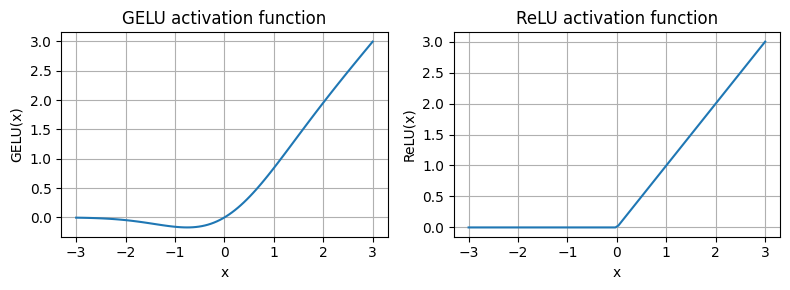

In [16]:
import matplotlib.pyplot as plt
gelu, relu = GELU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)
plt.tight_layout()
plt.show()

The smoothness of GELU can lead to better optimization properties during training,
as it allows for more nuanced adjustments to the model’s parameters. In contrast,
ReLU has a sharp corner at zero (figure 4.18, right), which can sometimes make opti-
mization harder, especially in networks that are very deep or have complex architec-
tures.

let’s use the GELU function to implement the small neural network module,
FeedForward, that we will be using in the LLM’s transformer block later.

In [17]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )
    def forward(self, x):
        return self.layers(x)

As we can see, the FeedForward module is a small neural network consisting of two
Linear layers and a GELU activation function. In the 124-million-parameter GPT
model, it receives the input batches with tokens that have an embedding size of 768
each via the GPT_CONFIG_124M dictionary where GPT_CONFIG_ 124M["emb_dim"] = 768.

![image.png](attachment:a1d9fe5e-a002-41a9-b5a8-27001d755a59.png)

In [18]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


Creates sample input
with batch dimension 2

The FeedForward module plays a crucial role in enhancing the model’s ability to learn
from and generalize the data. Although the input and output dimensions of this
module are the same, it internally expands the embedding dimension into a higher-
dimensional space through the first linear layer.

![image.png](attachment:26f4d4ff-716c-4f39-900c-f8dce1ce2ac4.png)

## Adding shortcut connections

Let’s discuss the concept behind shortcut connections, also known as skip or residual
connections. Originally, shortcut connections were proposed for deep networks in
computer vision (specifically, in residual networks) to mitigate the challenge of van-
ishing gradients. The vanishing gradient problem refers to the issue where gradients
(which guide weight updates during training) become progressively smaller as they
propagate backward through the layers, making it difficult to effectively train earlier
layers.

shortcut connection creates an alternative, shorter path
for the gradient to flow through the network by skipping one or more layers, which is
achieved by adding the output of one layer to the output of a later layer. This is why
these connections are also known as skip connections. They play a crucial role in pre-
serving the flow of gradients during the backward pass in training.

![image.png](attachment:52ff1d13-dc96-4370-be8f-91467205da8d.png)

In [19]:
# A neural network to illustrate shortcut connections

class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x

The code implements a deep neural network with five layers, each consisting of a
Linear layer and a GELU activation function. In the forward pass, we iteratively pass the
input through the layers and optionally add the shortcut connections if the self.use_
shortcut attribute is set to True.

In [20]:
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
layer_sizes, use_shortcut=False
)

In [21]:
def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])
    loss = nn.MSELoss()
    loss = loss(output, target)
    loss.backward()
    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [22]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.00012011159560643137
layers.2.0.weight has gradient mean of 0.0007152040489017963
layers.3.0.weight has gradient mean of 0.0013988736318424344
layers.4.0.weight has gradient mean of 0.005049645435065031


This code specifies a loss function that computes how close the model output and a
user-specified target (here, for simplicity, the value 0) are. Then, when calling
loss.backward(), PyTorch computes the loss gradient for each layer in the model. We
can iterate through the weight parameters via model.named_parameters(). Suppose we
have a 3 × 3 weight parameter matrix for a given layer. In that case, this layer will have
3 × 3 gradient values, and we print the mean absolute gradient of these 3 × 3 gradient
values to obtain a single gradient value per layer to compare the gradients between
layers more easily.

The output of the print_gradients function shows, the gradients become smaller
as we progress from the last layer (layers.4) to the first layer (layers.0), which is
a phenomenon called the vanishing gradient problem.

In [23]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169798612594604
layers.1.0.weight has gradient mean of 0.20694111287593842
layers.2.0.weight has gradient mean of 0.3289700150489807
layers.3.0.weight has gradient mean of 0.26657330989837646
layers.4.0.weight has gradient mean of 1.3258544206619263


The last layer (layers.4) still has a larger gradient than the other layers. However,
the gradient value stabilizes as we progress toward the first layer (layers.0) and
doesn’t shrink to a vanishingly small value.
In conclusion, shortcut connections are important for overcoming the limitations
posed by the vanishing gradient problem in deep neural networks.

## Connecting attention and linear layers in a transformer block

Now, let’s implement the transformer block, a fundamental building block of GPT and
other LLM architectures. This block, which is repeated a dozen times in the 124-million-
parameter GPT-2 architecture, combines several concepts we have previously covered:
multi-head attention, layer normalization, dropout, feed forward layers, and GELU
activations.

When a transformer block pro-
cesses an input sequence, each element in the sequence (for example, a word or sub-
word token) is represented by a fixed-size vector (in this case, 768 dimensions). The
operations within the transformer block, including multi-head attention and feed for-
ward layers, are designed to transform these vectors in a way that preserves their
dimensionality.

The idea is that the self-attention mechanism in the multi-head attention block iden-
tifies and analyzes relationships between elements in the input sequence.

![image.png](attachment:7ea8ac84-ed63-4cf1-bb1b-d2e80cb39301.png)

In [24]:
# MultiHeadAttemtion class
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)

        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        return context_vec

In [25]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
    # Shorcut connection for attention block
    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut # add original input back
        # shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut # add the original input back

        return x

The given code defines a TransformerBlock class in PyTorch that includes a multi-head
attention mechanism (MultiHeadAttention) and a feed forward network (Feed-
Forward), both configured based on a provided configuration dictionary (cfg), such
as GPT_CONFIG_124M.

Layer normalization (LayerNorm) is applied before each of these two components,
and dropout is applied after them to regularize the model and prevent overfitting. This
is also known as Pre-LayerNorm. Older architectures, such as the original transformer
model, applied layer normalization after the self-attention and feed forward networks
instead, known as Post-LayerNorm, which often leads to worse training dynamics.
Shortcut connection for attention block

In [26]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768) # CREATES SAMPLE INPUT OF SHAPE [batch_size, num_tokens, emb_dim]
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


As we can see, the transformer block maintains the input dimensions in its output, indi-
cating that the transformer architecture processes sequences of data without altering
their shape throughout the network.

The preservation of shape throughout the transformer block architecture is not
incidental but a crucial aspect of its design. This design enables its effective applica-
tion across a wide range of sequence-to-sequence tasks, where each output vector
directly corresponds to an input vector, maintaining a one-to-one relationship.

## Coding the GPT model

![image.png](attachment:559b2a42-45cc-4aec-92f7-682940a822a7.png)

In [27]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [28]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


As we can see, the output tensor has the shape [2, 4, 50257], since we passed in two
input texts with four tokens each. The last dimension, 50257, corresponds to the
vocabulary size of the tokenizer. Later, we will see how to convert each of these 50,257-
dimensional output vectors back into tokens.

In [29]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


Now, a curious reader might notice a discrepancy. Earlier, we spoke of initializing
a 124-million-parameter GPT model, so why is the actual number of parameters
163 million?

The reason is a concept called weight tying, which was used in the original GPT-2
architecture. It means that the original GPT-2 architecture reuses the weights from
the token embedding layer in its output layer.

In [30]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


The token embedding and output layers are very large due to the number of rows for
the 50,257 in the tokenizer’s vocabulary. Let’s remove the output layer parameter
count from the total GPT-2 model count according to the weight tying:

In [31]:
total_params_gpt2 = (
    total_params - sum(p.numel()
    for p in model.out_head.parameters())
)
print(f"Number of trainable parameters "
    f"considering weight tying: {total_params_gpt2:,}"
)

Number of trainable parameters considering weight tying: 124,412,160


In [32]:
total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024 * 1024)
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


In conclusion, by calculating the memory requirements for the 163 million parame-
ters in our GPTModel object and assuming each parameter is a 32-bit float taking up 4
bytes, we find that the total size of the model amounts to 621.83 MB, illustrating the
relatively large storage capacity required to accommodate even relatively small LLMs.

## Generating text

![image.png](attachment:387aaff0-db7b-429d-ae26-13a279326558.png)

The vector corre-
sponding to the next token is extracted and converted into a probability distribution via
the softmax function. Within the vector containing the resulting probability scores, the
index of the highest value is located, which translates to the token ID. This token ID is
then decoded back into text, producing the next token in the sequence. Finally, this
token is appended to the previous inputs, forming a new input sequence for the subse-
quent iteration. This step-by-step process enables the model to generate text sequen-
tially, building coherent phrases and sentences from the initial input context.

![image.png](attachment:ce7cab19-3e9f-48b9-ad1c-e21b93ed492f.png)

This code demonstrates a simple implementation of a generative loop for a lan-
guage model using PyTorch. It iterates for a specified number of new tokens to be
generated, crops the current context to fit the model’s maximum context size, com-
putes predictions, and then selects the next token based on the highest probability
prediction.

In [33]:
def generate_text_simple(model, idx, max_new_tokens, context_size): # idx is a (batch, n_tokens)array of indices in the current context.
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :] # focuses only on the last time step(batch, n_token, vocab_size) becomes(batch, vocab_size)
        probas = torch.softmax(logits, dim=-1) # probas has shape(batch, vocab_size)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True) # idx_next has shape(batch,1)
        idx = torch.cat((idx, idx_next), dim=1) # appends sampled index to the running sequence where idx has shape(batch, n_tokens+1)
    return idx

In [34]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


![image.png](attachment:12b4384e-d20b-487a-8df9-cb349a39bf50.png)

In [35]:
model.eval()
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


In [36]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


As we can see, the model generated gibberish, which is not at all like the coherent text
Hello, I am a model ready to help. What happened? The reason the model is unable to
produce coherent text is that we haven’t trained it yet. So far, we have only implemented
the GPT architecture and initialized a GPT model instance with initial random weights.

# Pretraining on Unlabeled Data
----------

![image.png](attachment:df9ec139-bacb-4a10-a289-78c31de1758d.png)

we have implemented the data sampling and attention mechanism and
coded the LLM architecture. It is now time to implement a training function and
pretrain the LLM. We will learn about basic model evaluation techniques to mea-
sure the quality of the generated text, which is a requirement for optimizing the
LLM during the training process.

## Evaluating generative text models

![image.png](attachment:5a962463-b844-49fe-a2c2-58d60d19f7a5.png)

Considering the GPT_CONFIG_124M dictionary, the only adjustment we have made com-
pared to the previous chapter is that we have reduced the context length (context_
length) to 256 tokens. This modification reduces the computational demands of
training the model, making it possible to carry out the training on a standard laptop
computer.

In [37]:
GPT_CONFIG_124M = {
    "vocab_size" : 50257,
    "context_length" : 256,
    "emb_dim" : 768,
    "n_heads" : 12,
    "n_layers" : 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

![image.png](attachment:83607959-25da-41f0-9eae-0eeecffe2be3.png)

In [38]:
import tiktoken
import torch
import torch.nn as nn

In [39]:
def generate_text_simple(model, idx, max_new_tokens, context_size): # idx is a (batch, n_tokens)array of indices in the current context.
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :] # focuses only on the last time step(batch, n_token, vocab_size) becomes(batch, vocab_size)
        probas = torch.softmax(logits, dim=-1) # probas has shape(batch, vocab_size)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True) # idx_next has shape(batch,1)
        idx = torch.cat((idx, idx_next), dim=1) # appends sampled index to the running sequence where idx has shape(batch, n_tokens+1)
    return idx

In [40]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special = {'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # adds the batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # removes batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model = model,
    idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens = 10,
    context_size = GPT_CONFIG_124M["context_length"]
)

print("Output Text: \m", token_ids_to_text(token_ids, tokenizer))

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_43894/287302562.py:20: SyntaxWarning: invalid escape sequence '\m'
  print("Output Text: \m", token_ids_to_text(token_ids, tokenizer))


Output Text: \m Every effort moves you Aeiman Byeswickattributeometer inspector Normandy freezerigrate


### Calculating the text generation loss

let’s explore techniques for numerically assessing text quality generated
during training by calculating a text generation loss. We will go over this topic step by
step with a practical example to make the concepts clear and applicable, beginning
with a short recap of how the data is loaded and how the text is generated via the
generate_text_simple function.

![image.png](attachment:0d6e0b8d-b67b-403f-97a4-659f504ffd36.png)

Consider these two input examples, which have already been mapped to token IDs

In [41]:
inputs = torch.tensor([[16833, 3626, 6100], # ["every effort moves",
                       [40,1107, 588]])    # "I really like"]

In [42]:
targets = torch.tensor([[3626, 6100, 345],   # ["effor moves you"
                       [1107, 588, 11311]])  # , "really like chocolate"]

Note that the targets are the inputs but shifted one position forward, a concept we
covered in chapter 2 during the implementation of the data loader. This shifting strat-
egy is crucial for teaching the model to predict the next token in a sequence.

Now we feed the inputs into the model to calculate logits vectors for the two input
examples, each comprising three tokens. Then we apply the softmax function to
transform these logits into probability scores

In [43]:
with torch.no_grad():
    logits = model(inputs)
probas = torch.softmax(logits, dim=-1)
print(probas.shape)

torch.Size([2, 3, 50257])


The first number, 2, corresponds to the two examples (rows) in the inputs, also known
as batch size. The second number, 3, corresponds to the number of tokens in each
input (row). Finally, the last number corresponds to the embedding dimensionality,
which is determined by the vocabulary size

In [44]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[36397],
         [39619],
         [20610]],

        [[ 8615],
         [49289],
         [47105]]])


Given that we have two input batches, each containing three tokens, applying the
argmax function to the probability scores

In [45]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1:"f" {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Gathering SerbianFriday


> The model produces random text that is different from the target text because it has
not been trained yet. We now want to evaluate the performance of the model’s gen-
erated text numerically via a loss

For each of the two input texts, we can print the initial softmax probability scores cor-
responding to the target tokens using the following code

In [46]:
text_idx = 0
target_probas_1 = probas[text_idx, [0,1,2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0,1,2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([2.3466e-05, 2.0531e-05, 1.1733e-05])
Text 2: tensor([4.2794e-05, 1.6248e-05, 1.1586e-05])


The goal of training an LLM is to maximize the likelihood of the correct token, which
involves increasing its probability relative to other tokens. This way, we ensure the
LLM consistently picks the target token—essentially the next word in the sentence—
as the next token it generates.

In [47]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([-10.6600, -10.7936, -11.3531, -10.0591, -11.0276, -11.3658])


![image.png](attachment:7912087c-1737-45a4-b811-50e1bf8dd83a.png)

In [48]:
avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.8765)


The goal is to get the average log probability as close to 0 as possible by updating the
model’s weights as part of the training process. However, in deep learning, the com-
mon practice isn’t to push the average log probability up to 0 but rather to bring the
negative average log probability down to 0. The negative average log probability is
simply the average log probability multiplied by –1,

In [49]:
neg_avg_log_probas = avg_log_probas * -1
print(neg_avg_log_probas)

tensor(10.8765)


> In deep learning, the term for turning this negative
value, –10.7940, into 10.7940, is known as the cross entropy loss.

>Cross entropy loss
>
>At its core, the cross entropy loss is a popular measure in machine learning and deep
learning that measures the difference between two probability distributions—typi-
cally, the true distribution of labels (here, tokens in a dataset) and the predicted dis-
tribution from a model (for instance, the token probabilities generated by an LLM).
In the context of machine learning and specifically in frameworks like PyTorch, the
cross_entropy function computes this measure for discrete outcomes, which is
similar to the negative average log probability of the target tokens given the model’s
generated token probabilities, making the terms “cross entropy” and “negative aver-
age log probability” related and often used interchangeably in practice.

In [50]:
print("Logits shape:", logits.shape)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


As we can see, the logits tensor has three dimensions: batch size, number of tokens,
and vocabulary size. The targets tensor has two dimensions: batch size and number
of tokens.

For the cross_entropy loss function in PyTorch, we want to flatten these tensors
by combining them over the batch dimension:

In [51]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()
print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


Remember that the targets are the token IDs we want the LLM to generate, and the
logits contain the unscaled model outputs before they enter the softmax function to
obtain the probability scores.
Previously, we applied the softmax function, selected the probability scores corre-
sponding to the target IDs, and computed the negative average log probabilities.

In [52]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.8765)


### Calculating the training and validation set losses

In [69]:
!pwd

/content


In [70]:
file_path = "./Build-an-LLM/data/the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as file:
    text_data = file.read()

In [71]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


With just 5,145 tokens, the text might seem too small to train an LLM, but as men-
tioned earlier, it’s for educational purposes so that we can run the code in minutes
instead of weeks. Plus, later we will load pretrained weights from OpenAI into our
GPTModel code.

![image.png](attachment:53b092f7-e7a6-4343-ac45-ab44ab85b359.png)

To implement the data splitting and loading, we first define a train_ratio to use 90%
of the data for training and the remaining 10% as validation data for model evalua-
tion during training

In [72]:
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [73]:
from torch.utils.data import Dataset, DataLoader

In [74]:
class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt)

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1:i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self,idx):
        return self.input_ids[idx], self.target_ids[idx]

In [75]:
def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [76]:
train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [77]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


Based on the preceding code output, we have nine training set batches with two sam-
ples and 256 tokens each. Since we allocated only 10% of the data for validation, there
is only one validation batch consisting of two input examples. As expected, the input
data (x) and target data (y) have the same shape (the batch size times the number of
tokens in each batch) since the targets are the inputs shifted by one position, as dis-
cussed in chapter 2.

In [78]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

In [79]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

By default, the calc_loss_loader function iterates over all batches in a given data
loader, accumulates the loss in the total_loss variable, and then computes and averages the loss over the total number of batches. Alternatively, we can specify a
smaller number of batches via num_batches to speed up the evaluation during model
training.

In [80]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.994733810424805
Validation loss: 10.982571601867676


## Training an LLM

![image.png](attachment:10e2fe5f-2f24-43b1-a5f8-76ca69eaa127.png)

In [81]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            loss.backward()
            optimizer.step()
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch + 1} (Step {global_step:06d}): "
                     f"Train loss {train_loss:.3f}, "
                     f"Val loss {val_loss:.3f}")

        generate_and_print_sample(
             model, tokenizer, device, start_context
        )
    return train_losses, val_losses, track_tokens_seen

In [82]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )
    model.train()
    return train_loss, val_loss

In [83]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model = model, idx = encoded,
            max_new_tokens = 50, context_size = context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

> AdamW
>
> Adam optimizers are a popular choice for training deep neural networks. However, in
our training loop, we opt for the AdamW optimizer. AdamW is a variant of Adam that
improves the weight decay approach, which aims to minimize model complexity and
prevent overfitting by penalizing larger weights. This adjustment allows AdamW to
achieve more effective regularization and better generalization; thus, AdamW is fre-
quently used in the training of LLMs.

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1
)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device, num_epochs=num_epochs, eval_freq=5,
    eval_iter=5, start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.781, Val loss 9.933
Ep 1 (Step 000005): Train loss 8.111, Val loss 8.339
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.661, Val loss 7.048


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
        epochs_seen, val_losses, linestyle="-.", label="Validation loss"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2 = ax1.twiny()
    ax2.plot(tokens_seen, train_losses, alpha=0)
    ax2.set_xlabel("Tokens seen")
    fig.tight_layout()
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

As we can see,
both the training and validation losses start to improve for the first epoch. However,
the losses start to diverge past the second epoch. This divergence and the fact that the
validation loss is much larger than the training loss indicate that the model is overfit-
ting to the training data. We can confirm that the model memorizes the training data
verbatim by searching for the generated text snippets, such as quite insensible to
the irony in the “The Verdict” text file.

![image.png](attachment:f9b74742-a651-459c-86e2-032c1fc35c77.png)

## Decoding strategies to control randomness

We begin by transferring the model back from the GPU to the CPU since infer-
ence with a relatively small model does not require a GPU. Also, after training, we put
the model into evaluation mode to turn off random components such as dropout:

In [ ]:
model.to("cpu")
model.eval()

Next, we plug the GPTModel instance (model) into the generate_text_simple func-
tion, which uses the LLM to generate one token at a time:

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text_simple(
    model=model,
    idx = text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size = GPT_CONFIG_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

As explained earlier, the generated token is selected at each generation step corre-
sponding to the largest probability score among all tokens in the vocabulary. This
means that the LLM will always generate the same outputs even if we run the preced-
ing generate_text_simple function multiple times on the same start context (Every
effort moves you).

### Temperature scaling

Let’s now look at temperature scaling, a technique that adds a probabilistic selection
process to the next-token generation task. Previously, inside the generate_text_simple
function, we always sampled the token with the highest probability as the next token
using torch.argmax, also known as greedy decoding. To generate text with more variety,
we can replace argmax with a function that samples from a probability distribution
(here, the probability scores the LLM generates for each vocabulary entry at each
token generation step).

In [ ]:
vocab = {
    "closer": 0,
    "every": 1,
    "effort": 2,
    "forward": 3,
    "inches": 4,
    "moves": 5,
    "pizza": 6,
    "toward": 7,
    "you": 8,
}

inverse_vocab = {v: k for k, v in vocab.items()}

In [ ]:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

As discussed in chapter 4, inside generate_text_simple, we convert the logits into
probabilities via the softmax function and obtain the token ID corresponding to the
generated token via the argmax function, which we can then map back into text via
the inverse vocabulary:

In [ ]:
probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()
print(inverse_vocab[next_token_id])

Since the largest logit value and, correspondingly, the largest softmax probability
score are in the fourth position (index position 3 since Python uses 0 indexing), the
generated word is "forward".
To implement a probabilistic sampling process, we can now replace argmax with
the multinomial function in PyTorch:

In [ ]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

The printed output is "forward" just like before. What happened? The multinomial
function samples the next token proportional to its probability score. In other words,
"forward" is still the most likely token and will be selected by multinomial most of
the time but not all the time. To illustrate this, let’s implement a function that repeats
this sampling 1,000 times:

In [ ]:
def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item()
             for i in range(1000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

In [ ]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

In [ ]:
temperatures = [1, 0.1, 5]
scaled_probas = [softmax_with_temperature(next_token_logits, T)
                 for T in temperatures]
x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i],
                   bar_width, label=f'Temperature = {T}')
ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

### Top-k sampling

We’ve now implemented a probabilistic sampling approach coupled with temperature
scaling to increase the diversity of the outputs. We saw that higher temperature values
result in more uniformly distributed next-token probabilities, which result in more
diverse outputs as it reduces the likelihood of the model repeatedly selecting the most
probable token. This method allows for the exploring of less likely but potentially
more interesting and creative paths in the generation process. However, one down-
side of this approach is that it sometimes leads to grammatically incorrect or com-
pletely nonsensical outputs such as every effort moves you pizza.

![image.png](attachment:81252711-97d5-4a15-bb47-984c31011a6a.png)

The top-k approach replaces all nonselected logits with negative infinity value (-inf),
such that when computing the softmax values, the probability scores of the non-top-k
tokens are 0, and the remaining probabilities sum up to 1.

In [ ]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)

In [ ]:
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float('-inf')),
    other=next_token_logits
)
print(new_logits)

In [ ]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

Now, let’s combine temperature sampling and top-k sampling to modify the generate_
text_simple function we used to generate text via the LLM earlier, creating a new
generate function.

In [ ]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float('-inf')).to(logits.device),
                logits
            )
        if temperature > 0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        if idx_next == eos_id:
            break
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

In [ ]:
torch.manual_seed(123)
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

## Loading and saving model weights in PyTorch

In [ ]:
torch.save(model.state_dict(), "model.pth")

"model.pth" is the filename where the state_dict is saved. The .pth extension is a
convention for PyTorch files, though we could technically use any file extension.
Then, after saving the model weights via the state_dict, we can load the model
weights into a new GPTModel model instance:

In [ ]:
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", map_location=device))
model.eval()

## Loading pretrained weights from OpenAI

Fortunately, OpenAI openly shared the weights of their GPT-2 models, thus elimi-
nating the need to invest tens to hundreds of thousands of dollars in retraining the
model on a large corpus ourselves. So, let’s load these weights into our GPTModel class
and use the model for text generation. Here, weights refer to the weight parameters
stored in the .weight attributes of PyTorch’s Linear and Embedding layers.

We accessed them earlier via model.parameters() when training the model.



In [ ]:
import urllib.request
url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch05/"
    "01_main-chapter-code/gpt_download.py"
)
filename = url.split('/')[-1]
urllib.request.urlretrieve(url, filename)

In [ ]:
from gpt_download import download_and_load_gpt2

In [ ]:
settings, params = download_and_load_gpt2(
    model_size="124M", models_dir="gpt2"
)

Assuming the execution of the previous code has completed, let’s inspect the contents
of settings and params:

In [ ]:
print("Settings:", settings)
print("Parameter dictionary keys:", params.keys())

The settings dictionary stores the
LLM architecture settings similarly to our manually defined GPT_CONFIG_124M settings.
The params dictionary contains the actual weight tensors.

In [ ]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

>OpenAI also shares the weights of
larger models: 355M, 774M, and 1558M. The overall architecture of these differently
sized GPT models is the same

![image.jpeg](https://github.com/m4zuu/Build-an-LLM/blob/main/images/Figure517.jpeg?raw=1)

After loading the GPT-2 model weights into Python, we still need to transfer them
from the settings and params dictionaries into our GPTModel instance. First, we cre-
ate a dictionary that lists the differences between the different GPT model sizes

In [ ]:
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

In [ ]:
# Let's load the smallest model

model_name = "gpt2-small (124M)"
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024})

OpenAI used bias vectors in the multi-head attention module’s linear layers to
implement the query, key, and value matrix computations. Bias vectors are not com-
monly used in LLMs anymore as they don’t improve the modeling performance and
are thus unnecessary.

In [ ]:
NEW_CONFIG.update({"qkv_bias": True})

In [ ]:
gpt = GPTModel(NEW_CONFIG)
gpt.eval()

the GPTModel instance is initialized with random weights for pretraining.
The last step to using OpenAI’s model weights is to override these random weights
with the weights we loaded into the params dictionary. For this, we will first define a
small assign utility function that checks whether two tensors or arrays (left and
right) have the same dimensions or shape and returns the right tensor as **trainable
PyTorch parameters**:

In [ ]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, "
            "Right: {right.shape}"
        )
    return torch.nn.Parameter(torch.tensor(right))

**Next, we define a load_weights_into_gpt function that loads the weights from the
params dictionary into a GPTModel instance gpt**

In [ ]:
import numpy as np

In [ ]:
def load_weights_into_gpt(gpt, params):  # sets the models positional and token embedding weights to those specified in params
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])

    for b in range(len(params["blocks"])): # iterates over each transformer block in the model
        q_w, k_w, v_w = np.split(  # the np.split function is used to divide the attention and bias weights into three equal parts of the query, key, and value components
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T)

        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])

# The original GPT-2 model by OpenAI reused the token embedding weights in the output layer to reduce the total number
# parameters, which is a concept known as weight trying.

we carefully match the weights from
OpenAI’s implementation with our GPTModel implementation. To pick a specific
example, OpenAI stored the weight tensor for the output projection layer for the
first transformer block as params["blocks"][0]["attn"]["c_proj"]["w"]. In our
implementation, this weight tensor corresponds to gpt.trf_blocks[b].att.out_proj
.weight, where gpt is a GPTModel instance.

Developing the load_weights_into_gpt function took a lot of guesswork since
OpenAI used a slightly different naming convention from ours. However, the assign
function would alert us if we try to match two tensors with different dimensions. Also,
if we made a mistake in this function, we would notice this, as the resulting GPT
model would be unable to produce coherent text.

In [ ]:
load_weights_into_gpt(gpt, params)
gpt.to(device)

In [ ]:
torch.manual_seed(123)
token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

We can be confident that we loaded the model weights correctly because the model can
produce coherent text. A tiny mistake in this process would cause the model to fail. In
the following chapters, we will work further with this pretrained model and fine-tune it
to classify text and follow instructions.

# Fine-Tuning for classification
---------

![image.jpeg](https://github.com/m4zuu/Build-an-LLM/blob/main/images/Figure61.jpeg?raw=1)

## Different categories of fine-tuning

The most common ways to fine-tune language models are instruction fine-tuning and
classification fine-tuning. **Instruction fine-tuning involves training a language model on
a set of tasks using specific instructions** to improve its ability to understand and execute tasks described in **natural language prompts**

In classification fine-tuning, a concept you might already be acquainted with if you
have a background in machine learning, the model is trained to recognize a specific set of class labels, such as “spam” and “not spam.” Examples of classification tasks extend
beyond LLMs and email filtering: they include identifying different species of plants
from images; categorizing news articles into topics like sports, politics, and technology;
and distinguishing between benign and malignant tumors in medical imaging.

The key point is that a classification fine-tuned model is restricted to predicting
classes it has encountered during its training. For instance, it can determine whether
something is “spam” or “not spam,”

## Preparing the dataset

![image.jpeg](https://github.com/m4zuu/Build-an-LLM/blob/main/images/Figure64.jpeg?raw=1)